# Customer Analytics Project: RFM Segmentation + Ecommerce Insights

## 1. Load data and check columns

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("RAW DATA")
orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
sessions = pd.read_csv(DATA_DIR / "sessions.csv")

print("Orders shape:", orders.shape, "| columns:", orders.columns.tolist())
print("Customers shape:", customers.shape, "| columns:", customers.columns.tolist())
print("Sessions shape:", sessions.shape, "| columns:", sessions.columns.tolist())

# Normalize column names to make later checks less sensitive to capitalization/spaces.
for df in (orders, customers, sessions):
    df.columns = df.columns.str.strip()

# Confirm key columns expected by the RFM calculation.
required = {"customer_id", "order_id", "order_date", "status", "price"}
missing = required - set(orders.columns)
if missing:
    raise ValueError(f"orders.csv is missing required columns: {sorted(missing)}")
if "customer_id" not in customers.columns:
    raise ValueError("customers.csv must contain customer_id")

Orders shape: (8000, 14) | columns: ['order_id', 'product_id', 'customer_id', 'order_date', 'shipping_date', 'status', 'price', 'promised_delivery_date', 'actual_delivery_date', 'marketing_campaign', 'discount_pct', 'payment_method', 'sales_channel', 'shipping_speed']
Customers shape: (2500, 6) | columns: ['customer_id', 'signup_date', 'city', 'age', 'gender', 'customer_segment']
Sessions shape: (37058, 13) | columns: ['event_id', 'customer_id', 'session_id', 'event', 'timestamp', 'product_category', 'purchase_or_not', 'marketing_campaign', 'sales_channel', 'cart_abandoned', 'abandonment_reason', 'customer_age', 'customer_gender']


## 2. Clean order fields and calculate net order value

Count only delivered orders as successful purchases. Cancelled orders are not purchases, and returned orders should normally be excluded from retained customer value. Change the amount calculation accordingly.

In [19]:
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
orders["status_clean"] = orders["status"].astype(str).str.strip().str.lower()
orders["price"] = pd.to_numeric(orders["price"], errors="coerce")

# Discount may be missing; treat missing discount as 0%.
if "discount_pct" in orders.columns:
    orders["discount_pct"] = pd.to_numeric(orders["discount_pct"], errors="coerce").fillna(0)
    # Protect against malformed percentages outside the expected 0–100 range.
    orders["discount_pct"] = orders["discount_pct"].clip(0, 100)
    orders["net_amount"] = orders["price"] * (1 - orders["discount_pct"] / 100)
else:
    orders["net_amount"] = orders["price"]
    

orders["net_amount"] = pd.to_numeric(orders["net_amount"], errors="coerce")
orders["net_amount"] = orders["net_amount"].clip(lower=0)

delivered = orders.loc[
    orders["status_clean"].eq("delivered")
    & orders["customer_id"].notna()
    & orders["order_id"].notna()
    & orders["order_date"].notna()
    & orders["net_amount"].notna()
].copy()

# Use the day after the latest order date as a consistent RFM reference date.
# For a production system, use the actual reporting date instead.
analysis_date = orders["order_date"].max().normalize() + pd.Timedelta(days=1)
print("Analysis date:", analysis_date.date())
print("Delivered order rows:", len(delivered))
print("Distinct delivered orders:", delivered["order_id"].nunique())

Analysis date: 2026-10-10
Delivered order rows: 7300
Distinct delivered orders: 7300


## 3. Build RFM for every customer

- **Recency:** days since the customer's latest delivered order. Lower is better.
- **Frequency:** number of distinct delivered orders. Higher is generally better.
- **Monetary:** total net spending on delivered orders. Higher is generally better.

A left join keeps customers who have never made a delivered purchase. Their R/F/M are set to 999 / 0 / 0 for segmentation purposes, and they receive a separate label rather than being silently dropped.

In [20]:
rfm_purchasers = delivered.groupby("customer_id").agg(
    LastPurchase=("order_date", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("net_amount", "sum")
).reset_index()

# Start with the customer master so customers with no delivered orders remain in the output.
rfm = customers[["customer_id"]].drop_duplicates().merge(
    rfm_purchasers, on="customer_id", how="left"
)

rfm["Frequency"] = rfm["Frequency"].fillna(0).astype(int)
rfm["Monetary"] = rfm["Monetary"].fillna(0).round(2)
rfm["Recency"] = (analysis_date - pd.to_datetime(rfm["LastPurchase"]).dt.normalize()).dt.days

# 999 is a clear placeholder for "no successful purchase yet"; it is not a real recency value.
rfm.loc[rfm["Frequency"].eq(0), "Recency"] = 90
rfm["Recency"] = rfm["Recency"].fillna(999).astype(int)

print("Customers in master:", customers["customer_id"].nunique())
print("Customers in RFM output:", rfm["customer_id"].nunique())
print("Never-purchasers:", int(rfm["Frequency"].eq(0).sum()))
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].replace(90, np.nan).describe().round(2))

Customers in master: 2500
Customers in RFM output: 2500
Never-purchasers: 229


,customer_id,LastPurchase,Frequency,Monetary,Recency
0,38584,2026-08-16 11:18:00,2,3781.01,55
1,65430,2026-09-21 16:46:00,1,1398.95,19
2,60694,2026-09-17 10:04:00,2,1509.08,23
3,30502,2026-09-30 22:43:00,3,26817.42,10
4,52975,2026-08-26 10:00:00,1,166.19,45


,Recency,Frequency,Monetary
count,2271.00,2500.00,2500.00
mean,20.51,2.92,8135.46
std,17.42,2.07,11801.07
min,1.00,0.00,0.00
25%,7.00,1.00,865.72
50%,15.00,3.00,2683.81
75%,30.50,4.00,10805.76
max,70.00,12.00,80332.20


## 4. Create interpretable RFM scores and business segments

Quantile scores rank customers relative to *this dataset*: Recency score 5 means more recent; Frequency and Monetary score 5 mean higher frequency/spending. Duplicate values are handled with rank-based quantiles.

The business labels below use transparent rules instead of arbitrary cluster IDs. Tune thresholds to the business's buying cycle and inspect the resulting segment profile. Because this dataset covers a limited period, "At Risk" means **inactive relative to the observed window**, not a proven prediction that someone will churn.

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
Customer_Segment,,,,,,
At Risk,507,47.32,1.57,4187.58,1179.94,20.28
Needs Nurturing,453,16.46,2.60,2074.93,1811.84,18.12
Loyal / Repeat,374,10.46,4.95,9165.92,4121.93,14.96
Champions,359,5.18,5.63,21586.24,17570.25,14.36
High Spending,278,20.45,3.56,18235.79,15705.20,11.12
Never Purchased,229,90.00,0.00,0.00,0.00,9.16
Recent / Promising,201,6.00,1.64,4692.86,1377.53,8.04
Low Engagement,99,24.99,1.41,861.36,726.67,3.96


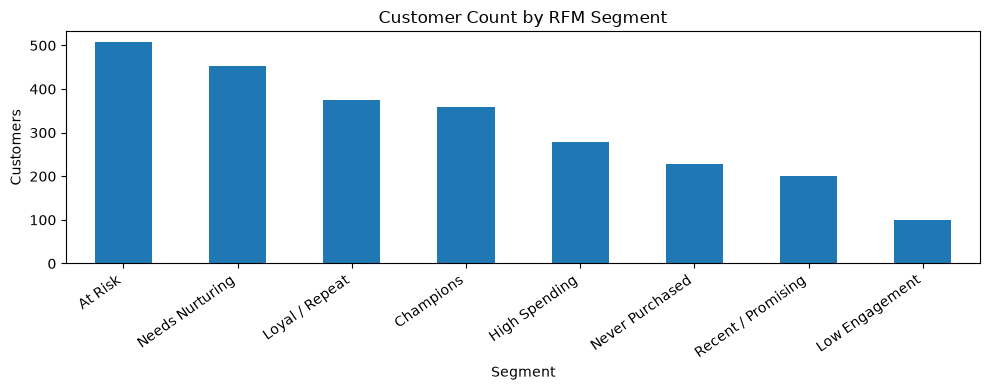

In [21]:
# Score only customers with at least one delivered purchase.
buyers = rfm["Frequency"].gt(0)

def quantile_score(series, higher_is_better=True, bins=5):
    # rank(method="first") lets qcut create bins even when many values are tied.
    ranked = series.rank(method="first", ascending=True)
    labels = list(range(1, bins + 1))
    if not higher_is_better:
        labels = labels[::-1]
    return pd.qcut(ranked, q=bins, labels=labels).astype(int)

rfm["R_Score"] = 0
rfm["F_Score"] = 0
rfm["M_Score"] = 0

rfm.loc[buyers, "R_Score"] = quantile_score(rfm.loc[buyers, "Recency"], higher_is_better=False)
rfm.loc[buyers, "F_Score"] = quantile_score(rfm.loc[buyers, "Frequency"], higher_is_better=True)
rfm.loc[buyers, "M_Score"] = quantile_score(rfm.loc[buyers, "Monetary"], higher_is_better=True)
rfm["RFM_Score"] = rfm[["R_Score", "F_Score", "M_Score"]].astype(str).agg("".join, axis=1)

# Use observed percentiles as adaptable cutoffs rather than hard-coded rupee values.
buyer_recency_75 = rfm.loc[buyers, "Recency"].quantile(0.75)
buyer_monetary_75 = rfm.loc[buyers, "Monetary"].quantile(0.75)

def assign_segment(row):
    if row["Frequency"] == 0:
        return "Never Purchased"
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    if row["F_Score"] >= 4 and row["R_Score"] >= 3:
        return "Loyal / Repeat"
    if row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent / Promising"
    if row["Recency"] >= buyer_recency_75 and row["F_Score"] <= 3:
        return "At Risk"
    if row["M_Score"] >= 4:
        return "High Spending"
    if row["R_Score"] <= 2 and row["F_Score"] <= 2 and row["M_Score"] <= 2:
        return "Low Engagement"
    return "Needs Nurturing"

rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)

segment_profile = rfm.groupby("Customer_Segment", dropna=False).agg(
    Customers=("customer_id", "nunique"),
    Avg_Recency=("Recency", lambda x: x[x < 999].mean()),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)
segment_profile["Customer_Percentage"] = (segment_profile["Customers"] / len(rfm) * 100).round(2)
display(segment_profile.sort_values("Customers", ascending=False))

# Visualize segment sizes to make the output presentation-ready.
rfm["Customer_Segment"].value_counts().plot(kind="bar", figsize=(10, 4))
plt.title("Customer Count by RFM Segment")
plt.xlabel("Segment")
plt.ylabel("Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 4A. Train a K-Means RFM model and save it as a `.pkl` file

**This is the machine-learning clustering part of the project.** K-Means discovers groups from Recency, Frequency, and Monetary values; it does not know business names such as “Valuable” or “At Risk”. After clustering, we inspect each cluster’s profile and assign an understandable business label. These labels are interpretations of the clusters, not ground-truth labels.

We cluster customers with at least one delivered order. Customers with no delivered orders are assigned **Never Purchased** separately because they do not have meaningful RFM values.

We log-transform the three features before scaling. This reduces the effect of highly skewed spending and makes the features more comparable. The saved `.pkl` bundle contains the fitted scaler, fitted K-Means model, feature names, and cluster-to-segment mapping.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
import pickle

# Use only meaningful RFM values for clustering. A customer with zero delivered orders
# is not included in K-Means; that customer will be labelled Never Purchased below.
rfm_features = ["Recency", "Frequency", "Monetary"]
cluster_mask = rfm["Frequency"].gt(0)
X_rfm = rfm.loc[cluster_mask, rfm_features].copy()

# RFM values should be non-negative for log1p. Clean any unexpected negative values.
X_rfm = X_rfm.clip(lower=0)

# Log transform reduces skew (especially in Monetary), then StandardScaler puts
# the three features on comparable scales for K-Means distance calculations.
X_log = np.log1p(X_rfm)

# K-Means is unsupervised: it learns clusters without pre-existing category labels.
N_CLUSTERS = 4  # Start with 4 groups; later compare 3, 4, 5 using silhouette + usefulness.
if len(X_log) < N_CLUSTERS:
    raise ValueError(f"Need at least {N_CLUSTERS} purchasing customers to fit K-Means.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=20)
cluster_ids = kmeans.fit_predict(X_scaled)

# Save the numeric cluster ID on each purchaser row. Never-purchasers remain -1.
rfm["KMeans_Cluster"] = -1
rfm.loc[cluster_mask, "KMeans_Cluster"] = cluster_ids

# Silhouette score is a rough clustering diagnostic (closer to 1 is better).
# It does NOT tell us whether the business labels are correct.
if len(set(cluster_ids)) > 1 and len(set(cluster_ids)) < len(cluster_ids):
    print("K-Means silhouette score:", round(silhouette_score(X_scaled, cluster_ids), 3))
else:
    print("Silhouette score unavailable because K-Means produced an unsuitable number of distinct clusters.")

print("Purchasing customers clustered:", int(cluster_mask.sum()))
print("Customers kept outside K-Means (never purchased):", int((~cluster_mask).sum()))


K-Means silhouette score: 0.311
Purchasing customers clustered: 2271
Customers kept outside K-Means (never purchased): 229


### Inspect clusters and map them to business categories

The model produces cluster IDs such as 0, 1, 2, and 3. These numbers have no inherent meaning. The next cell profiles each cluster using its average Recency, Frequency, and Monetary value, then maps the clusters to four business-friendly categories.

- **At Risk / Inactive:** the cluster with the highest average recency (longest time since purchase). This is an inactivity signal, not a proven churn prediction.
- **Valuable Customer:** among remaining clusters, the strongest combination of frequency, spending, and recency.
- **Repeat Customer:** among remaining clusters, the highest average purchase frequency.
- **Recent Customer:** the remaining cluster, typically representing a different/newer purchasing pattern.

Because each cluster is forced into one label, review the profile table before using these labels for business decisions. If the clusters do not separate these behaviors well, test a different number of clusters or use rule-based segments alongside K-Means.

### Save the complete K-Means model bundle as a pickle file

The `.pkl` file saves the **fitted scaler + fitted K-Means model + cluster-label mapping**. The log transform is applied in the prediction function below, so the same preprocessing is used for future customers. Do not load pickle files from unknown sources.

In [23]:
# Build a raw-value profile for interpretation (not for model fitting).
cluster_profile = rfm.loc[cluster_mask].groupby("KMeans_Cluster").agg(
    Customers=("customer_id", "nunique"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
).round(2)

# Rank clusters on each behavior. Percentile ranks make the combination comparable.
cluster_profile["Recency_Rank"] = cluster_profile["Avg_Recency"].rank(pct=True)
cluster_profile["Frequency_Rank"] = cluster_profile["Avg_Frequency"].rank(pct=True)
cluster_profile["Monetary_Rank"] = cluster_profile["Avg_Monetary"].rank(pct=True)
cluster_profile["Value_Score"] = (
    cluster_profile["Frequency_Rank"] + cluster_profile["Monetary_Rank"]
    + (1 - cluster_profile["Recency_Rank"])
)

display(cluster_profile.sort_values("Value_Score", ascending=False))

# Assign each business label to a different cluster. This mapping is based on the
# current dataset's cluster profiles and should be reviewed after every retraining.
remaining = list(cluster_profile.index)
cluster_to_segment = {}

# Longest average time since purchase -> At Risk / Inactive.
at_risk_cluster = int(cluster_profile.loc[remaining, "Avg_Recency"].idxmax())
cluster_to_segment[at_risk_cluster] = "At Risk / Inactive"
remaining.remove(at_risk_cluster)

# Highest combined value score among remaining clusters -> Valuable Customer.
valuable_cluster = int(cluster_profile.loc[remaining, "Value_Score"].idxmax())
cluster_to_segment[valuable_cluster] = "Valuable Customer"
remaining.remove(valuable_cluster)

# Highest average order frequency among remaining clusters -> Repeat Customer.
repeat_cluster = int(cluster_profile.loc[remaining, "Avg_Frequency"].idxmax())
cluster_to_segment[repeat_cluster] = "Repeat Customer"
remaining.remove(repeat_cluster)

# The final cluster gets the Recent Customer label; validate its profile below.
if remaining:
    cluster_to_segment[int(remaining[0])] = "Recent Customer"

rfm["KMeans_Segment"] = rfm["KMeans_Cluster"].map(cluster_to_segment)
rfm.loc[~cluster_mask, "KMeans_Segment"] = "Never Purchased"

cluster_profile["Business_Segment"] = cluster_profile.index.map(cluster_to_segment)
display(cluster_profile[["Customers", "Avg_Recency", "Avg_Frequency", "Avg_Monetary", "Business_Segment"]])
display(rfm[["customer_id", "Recency", "Frequency", "Monetary", "KMeans_Cluster", "KMeans_Segment"]].head(20))


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Recency_Rank,Frequency_Rank,Monetary_Rank,Value_Score
KMeans_Cluster,,,,,,,,,
2,549,6.00,5.56,19206.64,15549.74,0.25,1.00,1.00,2.75
1,665,24.83,3.42,12141.67,7964.67,0.75,0.75,0.75,1.75
3,429,6.76,2.52,2287.31,1723.40,0.50,0.50,0.50,1.50
0,628,38.02,1.43,1176.33,824.35,1.00,0.25,0.25,0.50


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Business_Segment
KMeans_Cluster,,,,,
0,628,38.02,1.43,1176.33,At Risk / Inactive
1,665,24.83,3.42,12141.67,Repeat Customer
2,549,6.00,5.56,19206.64,Valuable Customer
3,429,6.76,2.52,2287.31,Recent Customer


,customer_id,Recency,Frequency,Monetary,KMeans_Cluster,KMeans_Segment
0,38584,55,2,3781.01,0,At Risk / Inactive
1,65430,19,1,1398.95,0,At Risk / Inactive
2,60694,23,2,1509.08,0,At Risk / Inactive
3,30502,10,3,26817.42,1,Repeat Customer
4,52975,45,1,166.19,0,At Risk / Inactive
5,91525,47,2,1357.54,0,At Risk / Inactive
6,48691,16,1,864.17,0,At Risk / Inactive
7,54543,8,3,2150.72,3,Recent Customer
8,27667,15,7,8484.59,2,Valuable Customer
9,82399,41,1,264.98,0,At Risk / Inactive


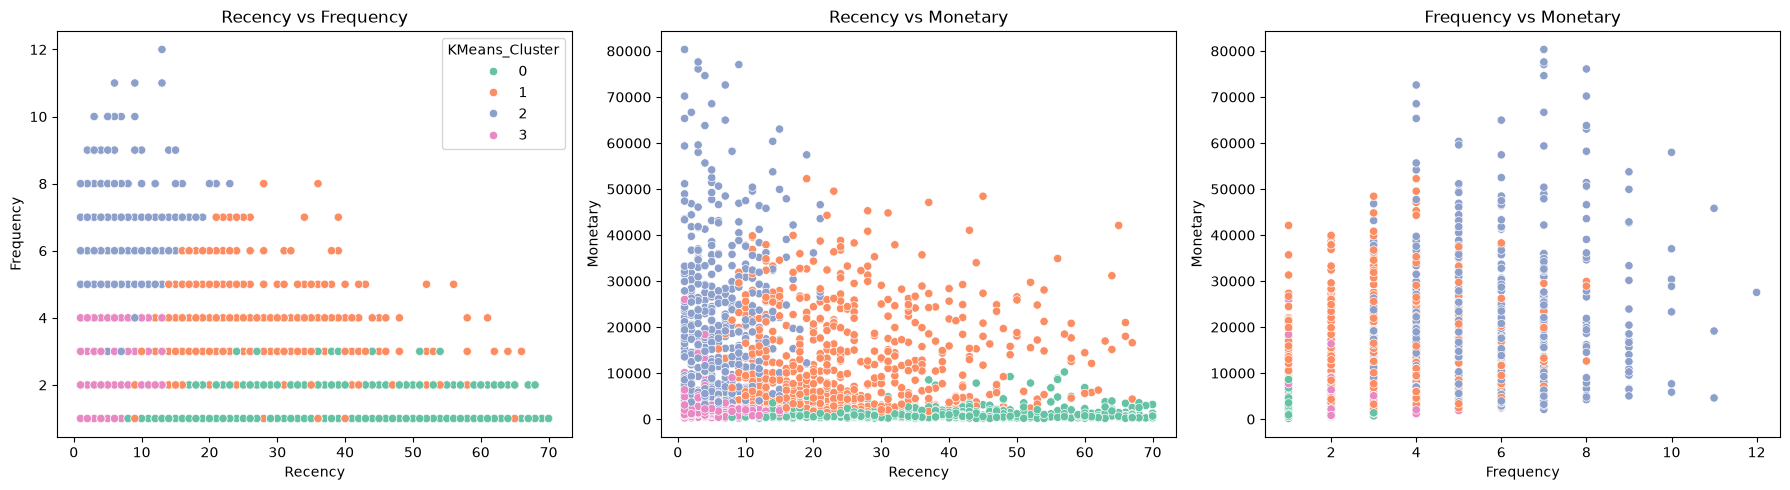

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

# Use only customers who have purchased
plot_data = rfm.loc[cluster_mask].copy()

# Create three scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=plot_data,
    x="Recency",
    y="Frequency",
    hue="KMeans_Cluster",
    palette="Set2",
    ax=axes[0]
)
axes[0].set_title("Recency vs Frequency")

sns.scatterplot(
    data=plot_data,
    x="Recency",
    y="Monetary",
    hue="KMeans_Cluster",
    palette="Set2",
    ax=axes[1],
    legend=False
)
axes[1].set_title("Recency vs Monetary")

sns.scatterplot(
    data=plot_data,
    x="Frequency",
    y="Monetary",
    hue="KMeans_Cluster",
    palette="Set2",
    ax=axes[2],
    legend=False
)
axes[2].set_title("Frequency vs Monetary")

plt.tight_layout()
plt.show()

In [25]:
# Package all parts needed for future predictions in one file.
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "rfm_kmeans_model.pkl"

model_bundle = {
    "feature_columns": rfm_features,
    "scaler": scaler,
    "kmeans": kmeans,
    "cluster_to_segment": cluster_to_segment,
    "never_purchase_label": "Never Purchased",
    "preprocessing": "clip negatives to 0, then np.log1p, then StandardScaler",
    "n_clusters": N_CLUSTERS,
}

with open(MODEL_PATH, "wb") as f:
    pickle.dump(model_bundle, f)

print(f"Saved trained K-Means model to: {MODEL_PATH.resolve()}")


Saved trained K-Means model to: C:\Users\tahseen\Downloads\E-Com_Pro2\models\rfm_kmeans_model.pkl


### Use the saved `.pkl` model to assign categories to customers

This function can take a table containing `customer_id`, `Recency`, `Frequency`, and `Monetary`. It returns a predicted cluster ID and its mapped business category. Customers with zero purchases are handled separately. The model should be retrained periodically as customer behavior changes.

In [26]:
def predict_rfm_segments(customer_rfm, model_path=MODEL_PATH):
    # Load the saved model bundle instead of fitting K-Means again.
    with open(model_path, "rb") as f:
        bundle = pickle.load(f)

    features = bundle["feature_columns"]
    result = customer_rfm.copy()
    result["Frequency"] = pd.to_numeric(result["Frequency"], errors="coerce").fillna(0)
    result["Recency"] = pd.to_numeric(result["Recency"], errors="coerce").fillna(999)
    result["Monetary"] = pd.to_numeric(result["Monetary"], errors="coerce").fillna(0)

    # Customers without successful purchases do not have meaningful RFM inputs.
    never_bought = result["Frequency"].le(0)
    result["Predicted_KMeans_Cluster"] = -1
    result["Predicted_Segment"] = bundle["never_purchase_label"]

    # Apply exactly the same transformations used during training.
    if (~never_bought).any():
        X_new = result.loc[~never_bought, features].clip(lower=0)
        X_new_log = np.log1p(X_new)
        X_new_scaled = bundle["scaler"].transform(X_new_log)
        predicted_clusters = bundle["kmeans"].predict(X_new_scaled)

        result.loc[~never_bought, "Predicted_KMeans_Cluster"] = predicted_clusters
        result.loc[~never_bought, "Predicted_Segment"] = pd.Series(predicted_clusters, index=result.index[~never_bought]).map(
            bundle["cluster_to_segment"]
        )

    return result

# Example: predict the category for every customer in the current RFM table.
predicted_customers = predict_rfm_segments(rfm)
display(predicted_customers[[
    "customer_id", "Recency", "Frequency", "Monetary",
    "Predicted_KMeans_Cluster", "Predicted_Segment"
]].head(25))

# Export a customer-by-customer prediction file for GitHub/Power BI analysis.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
predicted_customers.to_csv(OUTPUT_DIR / "kmeans_customer_predictions.csv", index=False)
print("Saved predictions to:", (OUTPUT_DIR / "kmeans_customer_predictions.csv").resolve())


,customer_id,Recency,Frequency,Monetary,Predicted_KMeans_Cluster,Predicted_Segment
0,38584,55,2,3781.01,0,At Risk / Inactive
1,65430,19,1,1398.95,0,At Risk / Inactive
2,60694,23,2,1509.08,0,At Risk / Inactive
3,30502,10,3,26817.42,1,Repeat Customer
4,52975,45,1,166.19,0,At Risk / Inactive
5,91525,47,2,1357.54,0,At Risk / Inactive
6,48691,16,1,864.17,0,At Risk / Inactive
7,54543,8,3,2150.72,3,Recent Customer
8,27667,15,7,8484.59,2,Valuable Customer
9,82399,41,1,264.98,0,At Risk / Inactive


Saved predictions to: C:\Users\tahseen\Downloads\E-Com_Pro2\outputs\kmeans_customer_predictions.csv


## 5. Question 1 — Which customers are valuable?

Champions and High Spending are useful starting lists. Review total spend and order frequency together: one expensive order can make a customer high-spending without making them loyal.

In [27]:

valuable_customers = rfm.loc[
    rfm["Customer_Segment"].isin(
        ["Champions", "High Spending", "Loyal / Repeat"]
    )
].sort_values(
    ["Monetary", "Frequency"],
    ascending=False
)

# Add customer profile fields for a usable marketing/CRM list.
profile_cols = [
    c for c in ["customer_id", "age", "gender", "city", "signup_date"]
    if c in customers.columns
]

valuable_customers = valuable_customers.merge(
    customers[profile_cols].drop_duplicates("customer_id"),
    on="customer_id",
    how="left",
    suffixes=("", "_profile")
)

# Select available columns and display the first 25 customers.
display_cols = [
    c for c in [
        "customer_id", "city", "age", "Frequency",
        "Monetary", "Recency", "RFM_Score", "Customer_Segment"
    ]
    if c in valuable_customers.columns
]

display(valuable_customers[display_cols].head(25))


,customer_id,city,age,Frequency,Monetary,Recency,RFM_Score,Customer_Segment
0,74779,Bengaluru,43,7,80332.20,1,555,Champions
1,69439,Navi Mumbai,40,7,77617.33,3,555,Champions
2,92180,Pune,42,7,77041.80,9,455,Champions
3,83214,Mumbai,32,8,76087.83,3,555,Champions
4,80130,Indore,31,7,74632.70,4,555,Champions
5,50726,Patna,42,4,72611.22,7,445,Champions
6,83922,Mumbai,44,8,70198.86,1,555,Champions
7,22506,Navi Mumbai,34,4,68525.87,5,445,Champions
8,81152,Kolkata,32,7,66674.47,2,555,Champions
9,95997,Jaipur,23,4,65335.16,1,545,Champions


## 6. Question 2 — Which customers may stop buying?

This is a **risk shortlist**, not a trained churn prediction. Use recent inactivity relative to your observed buyers' recency distribution. To claim predictive performance, create a future outcome label (for example, no delivered order in the next 30 days) and evaluate on a time-based holdout.

In [28]:
at_risk_customers = rfm.loc[rfm["Customer_Segment"].eq("At Risk")].sort_values(
    ["Recency", "Monetary"], ascending=[False, False]
)
print("At-risk customers:", len(at_risk_customers))
display(at_risk_customers[["customer_id", "Recency", "Frequency", "Monetary", "RFM_Score", "Customer_Segment"]].head(30))

At-risk customers: 507


,customer_id,Recency,Frequency,Monetary,RFM_Score,Customer_Segment
1789,88139,70,1,3186.61,113,At Risk
1455,99197,70,1,1276.38,112,At Risk
2490,65555,70,1,671.85,121,At Risk
2075,69328,70,1,662.74,111,At Risk
1670,87329,70,1,622.86,111,At Risk
1967,60851,70,1,320.42,111,At Risk
38,99906,70,1,224.78,111,At Risk
1992,56158,69,1,2949.88,113,At Risk
217,57695,69,1,265.04,111,At Risk
1005,38110,69,1,262.38,111,At Risk


## 10. Question 3 — Which segment should receive which offer?

Use offers that fit the customer's observed behavior. These are testable hypotheses, not guaranteed outcomes. Avoid discounting customers who already buy frequently unless there is a clear incremental goal.

In [29]:
offer_map = {
    "Champions": "VIP access, loyalty rewards, early access; avoid unnecessary blanket discounts",
    "Loyal / Repeat": "Points multiplier, bundles, cross-sell related products",
    "Recent / Promising": "Second-purchase incentive or complementary product recommendation",
    "At Risk": "Win-back message; test a targeted incentive and remind them of relevant products",
    "High Spending": "Premium products, replenishment reminders, service benefits",
    "Low Engagement": "Low-cost reactivation test; personalize using viewed/purchased categories",
    "Needs Nurturing": "Educational content, bestsellers, and category-specific recommendations",
    "Never Purchased": "First-purchase onboarding offer; clarify delivery, returns and payment trust"
}
rfm["Recommended_Offer"] = rfm["Customer_Segment"].map(offer_map)
display(rfm[["customer_id", "Customer_Segment", "Recency", "Frequency", "Monetary", "Recommended_Offer"]].head(25))

,customer_id,Customer_Segment,Recency,Frequency,Monetary,Recommended_Offer
0,38584,At Risk,55,2,3781.01,Win-back message; test a targeted incentive an...
1,65430,Needs Nurturing,19,1,1398.95,"Educational content, bestsellers, and category..."
2,60694,Low Engagement,23,2,1509.08,Low-cost reactivation test; personalize using ...
3,30502,High Spending,10,3,26817.42,"Premium products, replenishment reminders, ser..."
4,52975,At Risk,45,1,166.19,Win-back message; test a targeted incentive an...
5,91525,At Risk,47,2,1357.54,Win-back message; test a targeted incentive an...
6,48691,Needs Nurturing,16,1,864.17,"Educational content, bestsellers, and category..."
7,54543,Needs Nurturing,8,3,2150.72,"Educational content, bestsellers, and category..."
8,27667,Loyal / Repeat,15,7,8484.59,"Points multiplier, bundles, cross-sell related..."
9,82399,At Risk,41,1,264.98,Win-back message; test a targeted incentive an...
